# Dense neural network baseline for heartbeat classification (N / S / V / F)

A fully connected neural network trained on the beat windows produced by `prepare_data.py`. It is the neural baseline for the comparison with the random forest and the 1D-CNN (`EDA.ipynb`, section 7). The data is used as prepared, without augmentation or additional features. Performance is measured with macro-F1, because 89% of the beats are N. The test set (DS2) is used only once, in section 5.

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
HIDDEN = (128, 64)
BATCH_SIZE = 128
LR = 1e-3
MAX_EPOCHS = 20
CLASSES = ["N", "S", "V", "F"]
LABELS = list(range(len(CLASSES)))
LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}

SRC_DIR = next(p / sub for p in [Path.cwd(), *Path.cwd().parents] for sub in ["", "src"]
               if (p / sub / "data" / "train.npz").exists())
DATA_DIR = SRC_DIR / "data"
OUT_DIR = SRC_DIR / "samuel_nn" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 1. Data

In [2]:
def load_split(name):
    d = np.load(DATA_DIR / f"{name}.npz")
    X = d["X"].astype(np.float32)
    y = np.array([LABEL_MAP[str(v)] for v in d["y"]])
    return X, y

X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")

pd.DataFrame({s: np.bincount(y, minlength=4) for s, y in [("train", y_train), ("val", y_val), ("test", y_test)]},
             index=CLASSES)

,train,val,test
N,38160,7694,44245
S,730,214,1837
V,2987,801,3220
F,384,30,388


## 2. Model
Architecture: `200 → Dense 128 → ReLU → Dense 64 → ReLU → Dense 4`, with 34,244 parameters.

The network capacity is sized to the training data. All 42,261 training beats come from only 18 patients, so a network that is large relative to the data can memorise patient-specific waveforms instead of learning what separates the classes.
- **Hidden layers:** two hidden layers give the network non-linear decision boundaries between the four classes.
- **Layer widths:** the widths shrink from 200 to 128 to 64, compressing the beat towards the 4-class output.
- **Parameter count:** with 34k parameters the model has fewer parameters than training beats.

In [3]:
class DenseNN(nn.Module):
    def __init__(self, hidden=HIDDEN, n_in=200, n_classes=4):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


print(f"parameters: {sum(p.numel() for p in DenseNN().parameters()):,}")

parameters: 34,244


## 3. Training setup
- **Loss: cross-entropy with square-root class weights.** Each class is weighted by $w_c = \sqrt{n / (K \cdot n_c)}$, where $n$ is the number of training beats, $K = 4$ the number of classes and $n_c$ the number of beats in class $c$. Errors on rare classes therefore cost more, but the weighting is deliberately moderate. Full inverse-frequency weighting would make one F beat count about 100 times as much as an N beat. Almost all F training beats come from a single patient (372 of 384 from record 208), so such a weight would push the network to memorise that patient.
- **Optimiser:** Adam, learning rate 1e-3, batch size 128, seed 42.
- **Early stopping:** the network is trained for up to 20 epochs and the epoch with the highest validation macro-F1 is kept. The validation patients are never used for training, and the test set stays reserved for the final evaluation.

In [4]:
counts = np.bincount(y_train, minlength=4)
class_w = np.sqrt(len(y_train) / (4 * counts))
pd.Series(class_w, index=CLASSES, name="class weight").round(2)

N    0.53
S    3.80
V    1.88
F    5.25
Name: class weight, dtype: float64

## 4. Training

In [5]:
@torch.no_grad()
def predict_logits(model, X, batch_size=4096):
    model.eval()
    return torch.cat([model(torch.from_numpy(X[i:i + batch_size]).to(device)) for i in range(0, len(X), batch_size)])


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)


torch.manual_seed(SEED)
loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)), batch_size=BATCH_SIZE,
                    shuffle=True, generator=torch.Generator().manual_seed(SEED))
model = DenseNN().to(device)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_w, dtype=torch.float32, device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
y_val_t = torch.from_numpy(y_val).to(device)

history, best_f1, best_state = [], -1.0, None
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    total = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
    val_logits = predict_logits(model, X_val)
    val_f1 = macro_f1(y_val, val_logits.argmax(1).cpu().numpy())
    history.append({"epoch": epoch, "train_loss": total / len(y_train),
                    "val_loss": criterion(val_logits, y_val_t).item(), "val_macro_f1": val_f1})
    if val_f1 > best_f1:
        best_f1, best_epoch, best_state = val_f1, epoch, copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
history = pd.DataFrame(history).set_index("epoch")
print(f"best epoch: {best_epoch} (val macro-F1 {best_f1:.4f})")
history.round(4)

best epoch: 1 (val macro-F1 0.4145)


,train_loss,val_loss,val_macro_f1
epoch,,,
1,0.3541,1.3126,0.4145
2,0.1758,1.4440,0.3608
3,0.1412,1.7792,0.3856
4,0.1159,1.6437,0.3027
5,0.1020,1.7207,0.3749
6,0.0895,1.9599,0.3413
7,0.0807,1.7729,0.3719
8,0.0763,1.7622,0.3423
9,0.0696,2.2364,0.3218


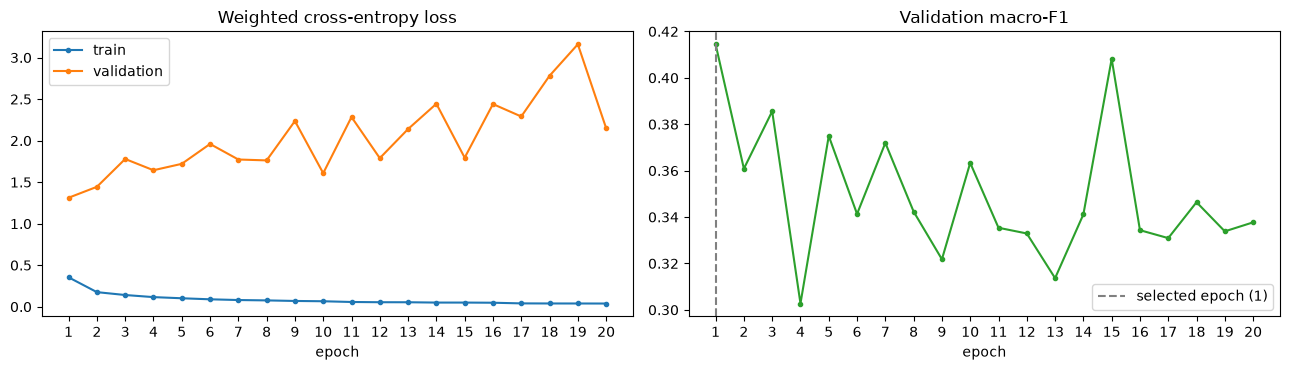

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(history.index, history.train_loss, marker="o", ms=3, label="train")
axes[0].plot(history.index, history.val_loss, marker="o", ms=3, label="validation")
axes[0].set_title("Weighted cross-entropy loss"); axes[0].legend()
axes[1].plot(history.index, history.val_macro_f1, marker="o", ms=3, color="tab:green")
axes[1].axvline(best_epoch, color="grey", ls="--", label=f"selected epoch ({best_epoch})")
axes[1].set_title("Validation macro-F1"); axes[1].legend()
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_xticks(history.index)
plt.tight_layout(); plt.show()

## 5. Results

In [7]:
def scores(y_true, y_pred):
    f1s = f1_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": macro_f1(y_true, y_pred),
            **{f"F1_{c}": f for c, f in zip(CLASSES, f1s)}}

y_val_pred = predict_logits(model, X_val).argmax(1).cpu().numpy()
y_test_pred = predict_logits(model, X_test).argmax(1).cpu().numpy()

for split, y_true, y_pred in [("VALIDATION", y_val, y_val_pred), ("TEST", y_test, y_test_pred)]:
    print(f"===== {split} =====")
    print(classification_report(y_true, y_pred, labels=LABELS, target_names=CLASSES, digits=4, zero_division=0))

results = pd.DataFrame([{"split": "val", **scores(y_val, y_val_pred)},
                        {"split": "test", **scores(y_test, y_test_pred)}]).set_index("split")
results.round(4)

===== VALIDATION =====
              precision    recall  f1-score   support

           N     0.9468    0.7720    0.8505      7694
           S     0.5000    0.0140    0.0273       214
           V     0.8382    0.7179    0.7734       801
           F     0.0034    0.2000    0.0067        30

    accuracy                         0.7465      8739
   macro avg     0.5721    0.4260    0.4145      8739
weighted avg     0.9226    0.7465    0.8204      8739

===== TEST =====
              precision    recall  f1-score   support

           N     0.9528    0.7432    0.8351     44245
           S     0.0394    0.0964    0.0559      1837
           V     0.3703    0.7783    0.5018      3220
           F     0.0036    0.0361    0.0065       388

    accuracy                         0.7161     49690
   macro avg     0.3415    0.4135    0.3498     49690
weighted avg     0.8738    0.7161    0.7782     49690



,accuracy,macro_f1,F1_N,F1_S,F1_V,F1_F
split,,,,,,
val,0.7465,0.4145,0.8505,0.0273,0.7734,0.0067
test,0.7161,0.3498,0.8351,0.0559,0.5018,0.0065


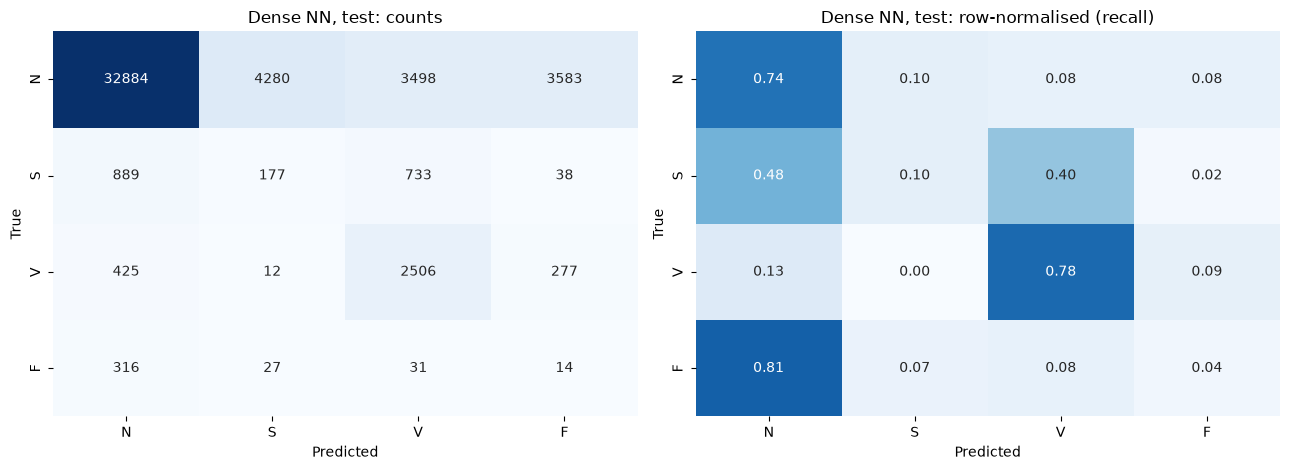

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
cm = confusion_matrix(y_test, y_test_pred, labels=LABELS)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[0].set_title("Dense NN, test: counts"); axes[1].set_title("Dense NN, test: row-normalised (recall)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

In [9]:
torch.save({"hidden": HIDDEN, "class_weights": class_w, "epoch": best_epoch, "state_dict": model.state_dict()},
           OUT_DIR / "dense_nn.pt")
np.savez(OUT_DIR / "dense_nn_predictions.npz", val_pred=y_val_pred, test_pred=y_test_pred,
         val_true=y_val, test_true=y_test, classes=np.array(CLASSES))
history.to_csv(OUT_DIR / "history.csv")
results.to_csv(OUT_DIR / "results.csv")
print("saved to", OUT_DIR)

saved to /home/sbabi/projects/D7043E-ADM-Group1/src/samuel_nn/outputs


## 6. Conclusions

| Split | Accuracy | Macro-F1 | F1 N | F1 S | F1 V | F1 F |
|---|---|---|---|---|---|---|
| Validation (4 patients) | 0.747 | 0.415 | 0.851 | 0.027 | 0.773 | 0.007 |
| **Test (22 patients)** | **0.716** | **0.350** | 0.835 | 0.056 | 0.502 | 0.007 |

- **The dense NN does not generalise well to unseen patients.** Training loss falls every epoch, from 0.35 to 0.04. Validation loss is lowest after the first epoch and rises from there, from 1.31 to about 2–3. Further training only fits the 18 training patients more closely, so early stopping keeps the epoch-1 model. On test it detects 78% of V beats, but it also labels 3,498 N beats as V and 3,583 as F, which brings V precision down to 0.37.
- **Cause:** a dense layer learns one weight per sample position, so it learns *where* in the window each training patient's waveform has a feature. The beats of a new patient have similar features at slightly different positions and amplitudes, and those weights don't transfer.
- **Implication:** this behaviour motivates a convolutional architecture. A convolution applies the same small filter at every position, so a feature it learns is recognised wherever it appears in the window.
- **Rare classes:** class weighting alone does not make S beats detectable (F1 0.06). S beats differ from N beats mainly in their timing, which the beat window alone does not contain.
